# Vietnam Commodity Price Analysis (2004 – Oct 2026)

**Business context.** Viet Nam is one of the world's largest exporters of rice, Robusta coffee and
natural rubber, and a net importer of fuel and fertilizer. Movements in world commodity prices
therefore hit farmers' income, exporters' margins and household costs directly.

**Business questions**
1. Which commodities have risen or fallen the most, over the last year and the last 10 years?
2. Which ones are the riskiest (most volatile) relative to the return they delivered?
3. Do Viet Nam's export crops show **seasonal** price patterns that a trader or farmer could plan around?
4. How is Vietnamese rice priced against its main competitor, Thai rice?
5. Do rising **input costs** (oil → fertilizer) feed through to rice prices?
6. How fast do world rice prices pass through to **domestic wholesale** prices in the Mekong Delta?

**Data**
- World Bank Commodity Price Data (*Pink Sheet*), monthly, nominal USD, updated Nov 2026.
- WFP Viet Nam food prices (wholesale rice in An Giang, Dong Thap, Bac Lieu), 2008 – 2022, via HDX.

In [1]:
import sys
from pathlib import Path

# Find the project root whether the notebook runs from notebooks/ or the repo root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "metrics.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from metrics import (load_prices, load_wholesale_rice, wide, rebase, scorecard,
                     seasonality, return_correlation, lagged_correlation)

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3,
                     "figure.dpi": 110})
IMG = str(ROOT / "images") + "/"
prices = load_prices()

# Analysis windows are derived from the data, so a refresh moves them automatically
END = prices["date"].max()                          # latest month in the data
START_10Y = END - pd.DateOffset(years=10, months=-1)  # 120 months ending at END
START_LONG = pd.Timestamp("2004-01-01")             # VN rice series starts Dec 2003
fmt = lambda d: f"{d:%b %Y}"
print(prices.shape, "| latest month:", fmt(END), "| 10-year window:", fmt(START_10Y), "–", fmt(END))
prices.head()

(9002, 5) | latest month: Oct 2026 | 10-year window: Nov 2016 – Oct 2026


,date,commodity,group,unit,price_usd
0,1960-01-01,Cocoa,Soft commodity,$/kg,0.63
1,1960-02-01,Cocoa,Soft commodity,$/kg,0.61
2,1960-03-01,Cocoa,Soft commodity,$/kg,0.58
3,1960-04-01,Cocoa,Soft commodity,$/kg,0.60
4,1960-05-01,Cocoa,Soft commodity,$/kg,0.60


## 1. Price scorecard — last 10 years (120 months to the latest month)

| Metric | Meaning |
|---|---|
| `yoy_%` | change vs. the same month last year |
| `cagr_%` | compound annual growth rate over the window |
| `volatility_%` | annualised std-dev of monthly log returns (risk) |
| `max_drawdown_%` | worst peak-to-trough fall inside the window |
| `vs_period_avg_%` | how expensive the commodity is today vs. its 10-year average |

In [2]:
w10 = wide(prices, START_10Y, END)
card = scorecard(w10)
card.style.format("{:,.1f}").background_gradient(subset=["yoy_%"], cmap="RdYlGn") \
    .background_gradient(subset=["volatility_%"], cmap="Oranges")

,latest,mom_%,yoy_%,cagr_%,volatility_%,max_drawdown_%,vs_period_avg_%
Crude oil (Brent),125.0,7.0,93.2,10.5,37.5,-71.1,72.7
Rubber (RSS3),2.8,2.9,41.5,4.3,24.1,-50.9,46.3
Rice (Thai 5%),489.0,1.5,37.4,3.0,18.3,-46.1,6.0
Copper,"14,508.0",0.2,35.1,10.4,15.4,-28.4,75.2
Sugar (world),0.4,4.9,26.5,-0.5,21.2,-48.9,16.5
Maize,226.5,-5.5,14.3,4.1,20.0,-51.1,8.7
Rice (VN 5%),413.9,-1.1,13.2,2.1,13.1,-45.4,-2.3
DAP (fertilizer),803.1,0.3,6.5,10.5,21.2,-52.3,55.3
Urea (fertilizer),420.0,3.1,6.5,7.5,43.5,-69.2,13.0
Gold,"4,105.0",-5.0,1.2,12.9,12.2,-18.9,95.3


## 2. Long-term trend (indexed, start of the 10-year window = 100)

Prices are in different units ($/kg, $/mt, $/bbl…), so each series is rebased to 100 to compare growth.

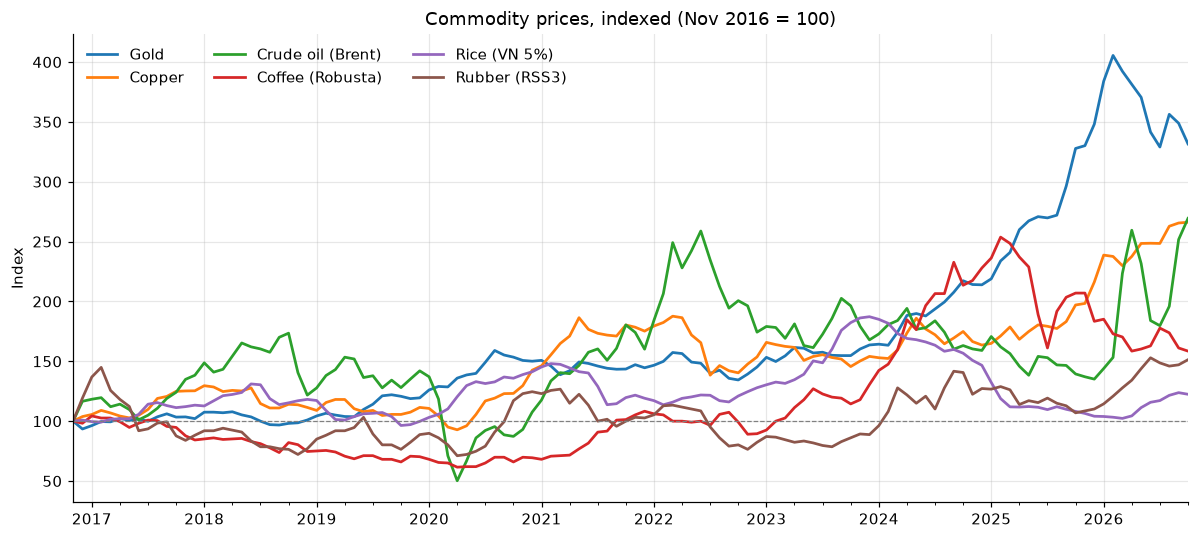

In [3]:
focus = ["Gold", "Copper", "Crude oil (Brent)", "Coffee (Robusta)", "Rice (VN 5%)", "Rubber (RSS3)"]
ax = rebase(w10[focus]).plot(lw=1.8)
ax.axhline(100, color="grey", lw=.8, ls="--")
ax.set(title=f"Commodity prices, indexed ({fmt(START_10Y)} = 100)", xlabel="", ylabel="Index")
ax.legend(ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(IMG + "01_indexed_trend.png"); plt.show()

## 3. Risk vs. return

Each dot is a commodity: x = volatility (risk), y = CAGR (return) over 10 years.
Top-left is the "best" place to be — high growth with low volatility.

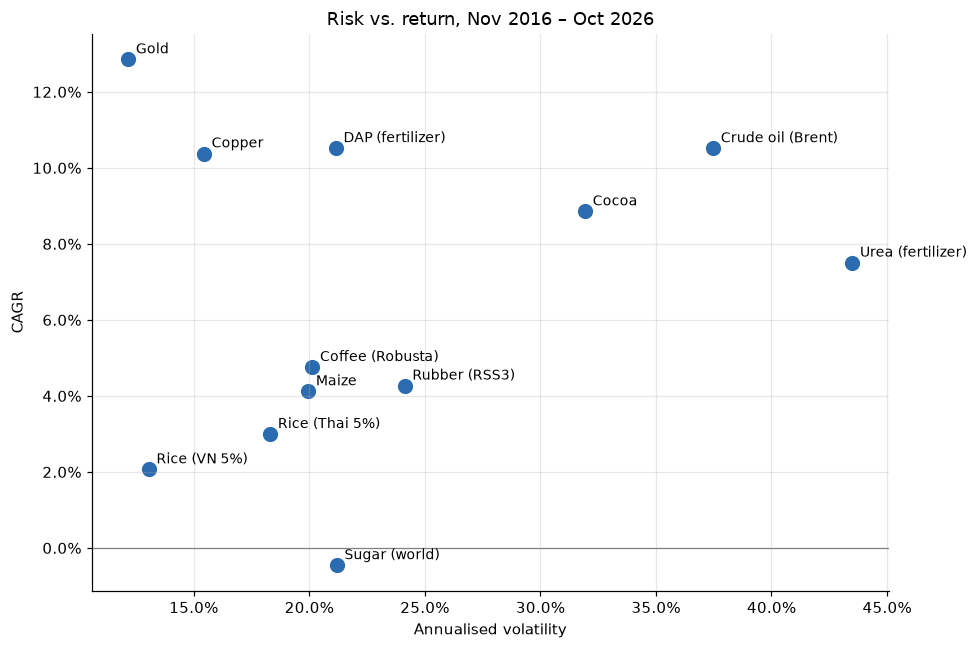

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(card["volatility_%"], card["cagr_%"], s=80, color="#2b6cb0")
for name, r in card.iterrows():
    ax.annotate(name, (r["volatility_%"], r["cagr_%"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title=f"Risk vs. return, {fmt(START_10Y)} – {fmt(END)}", xlabel="Annualised volatility", ylabel="CAGR")
plt.tight_layout(); plt.savefig(IMG + "02_risk_return.png"); plt.show()

## 4. Seasonality of Viet Nam's export crops

Average % deviation from the 12-month moving average, by calendar month (2004 – 2026).
Positive = prices are usually above trend that month.

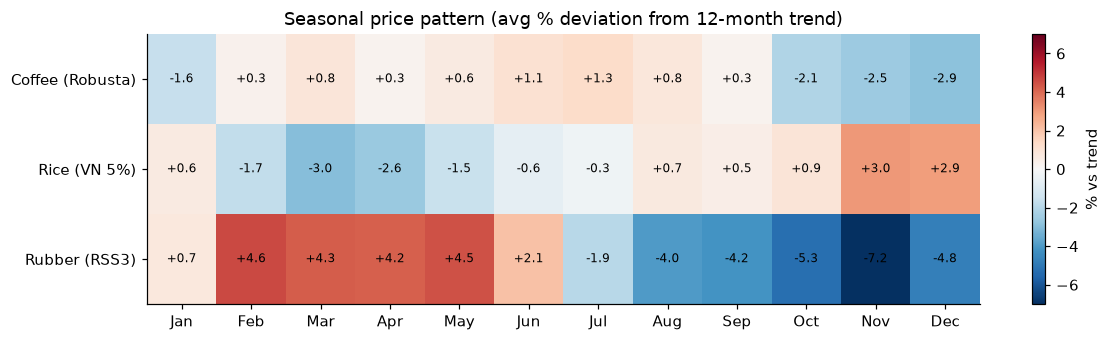

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Coffee (Robusta),-1.6,0.3,0.8,0.3,0.6,1.1,1.3,0.8,0.3,-2.1,-2.5,-2.9
Rice (VN 5%),0.6,-1.7,-3.0,-2.6,-1.5,-0.6,-0.3,0.7,0.5,0.9,3.0,2.9
Rubber (RSS3),0.7,4.6,4.3,4.2,4.5,2.1,-1.9,-4.0,-4.2,-5.3,-7.2,-4.8


In [5]:
w_long = wide(prices, START_LONG, END)
crops = ["Coffee (Robusta)", "Rice (VN 5%)", "Rubber (RSS3)"]
season = pd.DataFrame({c: seasonality(w_long[c]) for c in crops}).T
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(season, cmap="RdBu_r", vmin=-7, vmax=7, aspect="auto")
ax.set_xticks(range(12), season.columns); ax.set_yticks(range(len(crops)), crops); ax.grid(False)
for i in range(season.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{season.iat[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="% vs trend")
ax.set_title("Seasonal price pattern (avg % deviation from 12-month trend)")
plt.tight_layout(); plt.savefig(IMG + "03_seasonality.png"); plt.show()
season.round(1)

## 5. Vietnamese vs. Thai rice — the price gap

Both are 5%-broken white rice, so the spread (Thai − Vietnamese) measures how much cheaper
Vietnamese rice is on the world market — Viet Nam's price competitiveness.

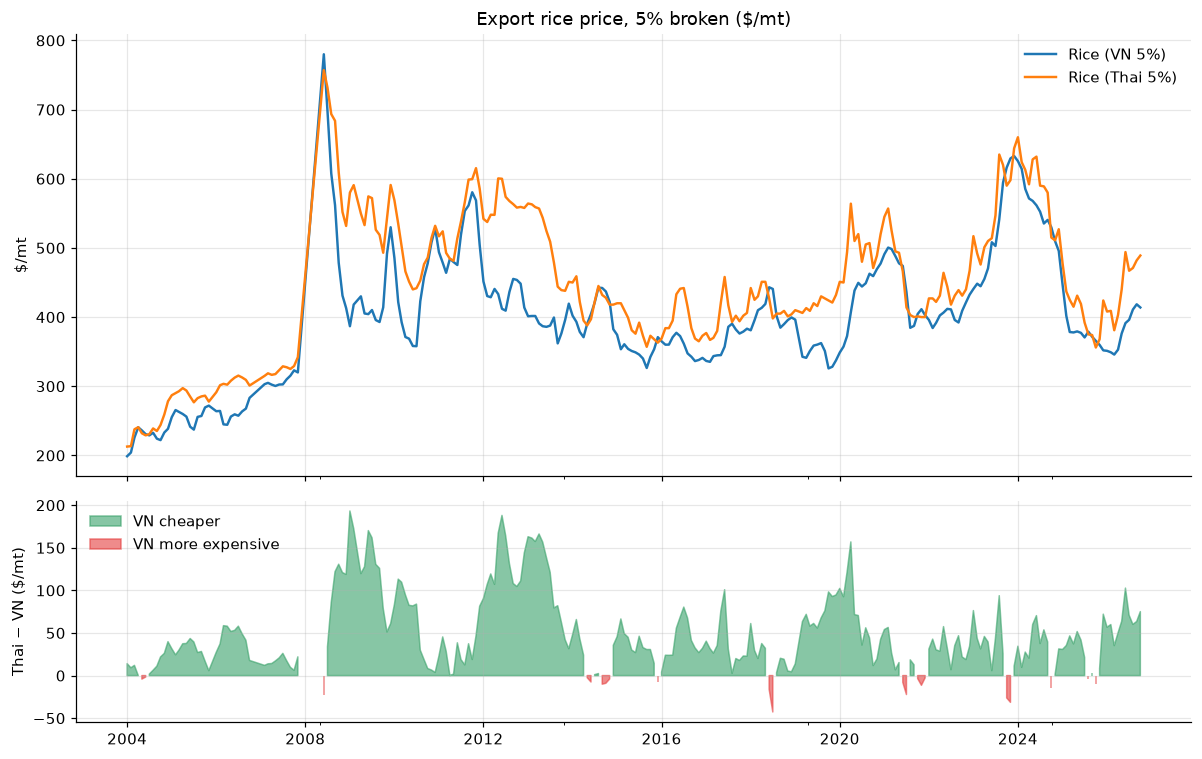

Average discount: $48/mt | months VN was MORE expensive: 8%


date,2004-12-31,2005-12-31,2006-12-31,2007-12-31,2008-12-31,2009-12-31,2010-12-31,2011-12-31,2012-12-31,2013-12-31,...,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31,2026-12-31
avg_spread_$,11.0,29.0,45.0,16.0,84.0,127.0,60.0,29.0,129.0,114.0,...,36.0,15.0,66.0,69.0,12.0,32.0,30.0,31.0,28.0,64.0


In [6]:
rice = w_long[["Rice (VN 5%)", "Rice (Thai 5%)"]].dropna()
spread = rice["Rice (Thai 5%)"] - rice["Rice (VN 5%)"]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
rice.plot(ax=a1, lw=1.6); a1.set(title="Export rice price, 5% broken ($/mt)", ylabel="$/mt"); a1.legend(frameon=False)
a2.fill_between(spread.index, spread, 0, where=spread >= 0, color="#38a169", alpha=.6, label="VN cheaper")
a2.fill_between(spread.index, spread, 0, where=spread < 0, color="#e53e3e", alpha=.6, label="VN more expensive")
a2.set(ylabel="Thai − VN ($/mt)"); a2.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(IMG + "04_rice_spread.png"); plt.show()
print(f"Average discount: ${spread.mean():.0f}/mt | months VN was MORE expensive: {(spread < 0).mean():.0%}")
spread.resample("YE").mean().to_frame("avg_spread_$").T.round(0)

## 6. Input costs: oil → fertilizer → rice?

Correlations use **monthly % changes**, not price levels (levels of trending series are
spuriously correlated). Lagged correlation checks whether a move today shows up *k* months later.

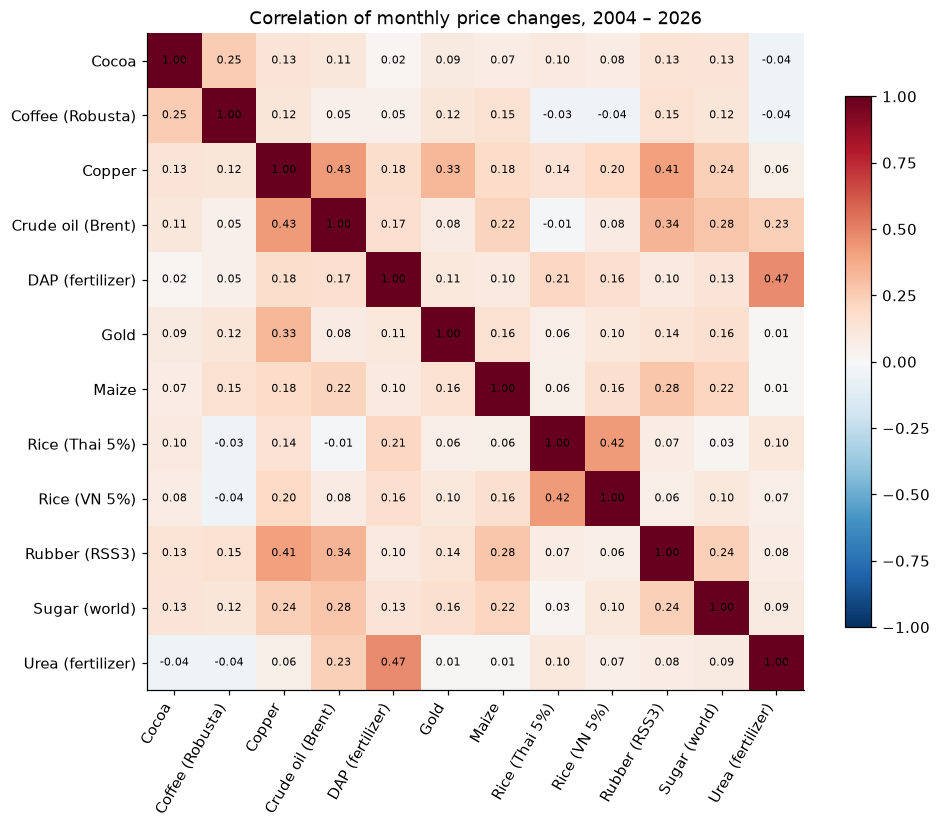

,Oil → Urea,Urea → Rice VN,Rice Thai → Rice VN
lag (months),,,
0,0.23,0.07,0.42
1,0.23,0.10,0.35
2,0.11,-0.06,0.13
3,0.02,-0.11,-0.09
4,-0.07,-0.08,-0.15
5,-0.03,-0.08,-0.06
6,0.12,-0.12,-0.23


In [7]:
corr = return_correlation(w_long)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Correlation of monthly price changes, 2004 – 2026")
plt.tight_layout(); plt.savefig(IMG + "05_correlation.png"); plt.show()

lags = pd.DataFrame({
    "Oil → Urea": lagged_correlation(w_long["Crude oil (Brent)"], w_long["Urea (fertilizer)"], 6),
    "Urea → Rice VN": lagged_correlation(w_long["Urea (fertilizer)"], w_long["Rice (VN 5%)"], 6),
    "Rice Thai → Rice VN": lagged_correlation(w_long["Rice (Thai 5%)"], w_long["Rice (VN 5%)"], 6),
})
lags.index.name = "lag (months)"
lags.round(2)

## 7. From world market to Mekong Delta — domestic wholesale rice

WFP wholesale rice prices (average of the Mekong markets, converted to $/mt) vs. the export price.

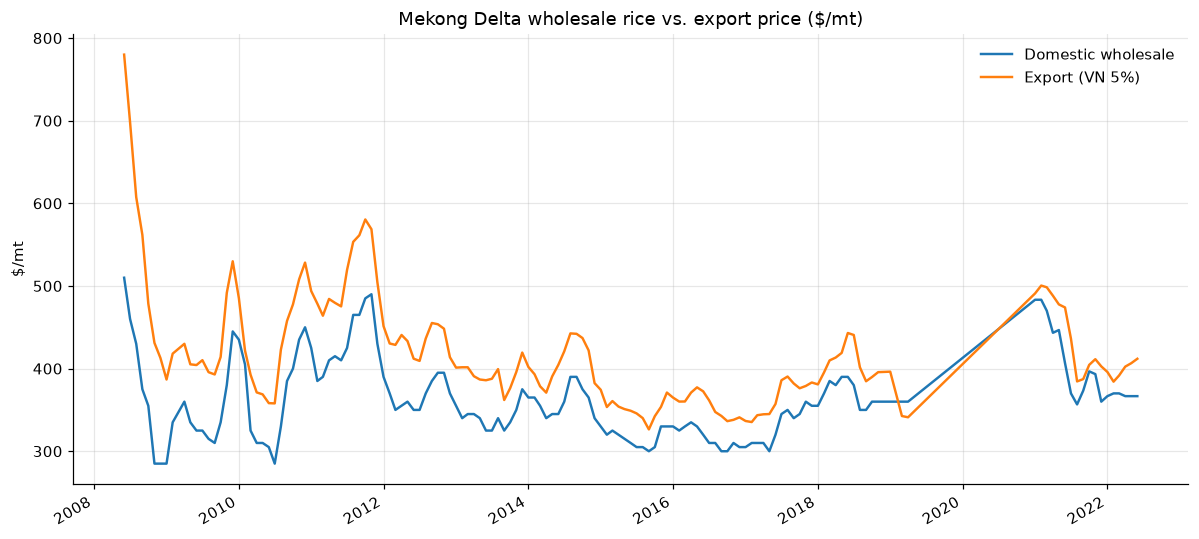

Domestic price = 88% of export price (median), IQR 85%–91%


,export → domestic
0,0.79
1,0.54
2,0.09
3,-0.06
4,-0.18


In [8]:
dom = load_wholesale_rice().groupby("date")["price_usd_kg"].mean() * 1000
# Keep a full monthly index (gaps = NaN) so lags below are true calendar months
dom = dom.asfreq("MS")
pt = pd.concat({"Domestic wholesale": dom, "Export (VN 5%)": w_long["Rice (VN 5%)"]}, axis=1, sort=True)
pt = pt.loc[dom.first_valid_index():dom.last_valid_index()]
ratio = (pt["Domestic wholesale"] / pt["Export (VN 5%)"]).dropna()
ax = pt.dropna().plot(lw=1.6, title="Mekong Delta wholesale rice vs. export price ($/mt)")
ax.set(xlabel="", ylabel="$/mt"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(IMG + "06_domestic_vs_export.png"); plt.show()
print(f"Domestic price = {ratio.median():.0%} of export price (median), IQR {ratio.quantile(.25):.0%}–{ratio.quantile(.75):.0%}")
lagged_correlation(pt["Export (VN 5%)"], pt["Domestic wholesale"], 4).round(2).to_frame("export → domestic")

## 8. Headline numbers (recomputed every run)

The written insights below quote these figures. If the data is refreshed, re-check the text against this table.

In [9]:
r = card
headline = pd.Series({
    "Latest month": fmt(END),
    "Brent YoY %": r.loc["Crude oil (Brent)", "yoy_%"],
    "Brent latest $/bbl": r.loc["Crude oil (Brent)", "latest"],
    "Rubber YoY %": r.loc["Rubber (RSS3)", "yoy_%"],
    "Copper YoY %": r.loc["Copper", "yoy_%"],
    "Gold 10y CAGR %": r.loc["Gold", "cagr_%"],
    "Gold volatility %": r.loc["Gold", "volatility_%"],
    "Gold vs 10y avg %": r.loc["Gold", "vs_period_avg_%"],
    "Coffee YoY %": r.loc["Coffee (Robusta)", "yoy_%"],
    "Coffee vs 10y avg %": r.loc["Coffee (Robusta)", "vs_period_avg_%"],
    "VN rice volatility %": r.loc["Rice (VN 5%)", "volatility_%"],
    "VN rice 10y CAGR %": r.loc["Rice (VN 5%)", "cagr_%"],
    "VN rice cheaper than Thai, % of months": (spread.dropna() > 0).mean() * 100,
    "Avg Thai − VN spread $/mt": spread.mean(),
    "Latest Thai − VN spread $/mt": spread.dropna().iloc[-1],
    "Domestic / export rice, median %": ratio.median() * 100,
})
headline.to_frame("value").style.format(lambda v: v if isinstance(v, str) else f"{v:,.1f}")

,value
Latest month,Oct 2026
Brent YoY %,93.2
Brent latest $/bbl,125.0
Rubber YoY %,41.5
Copper YoY %,35.1
Gold 10y CAGR %,12.9
Gold volatility %,12.2
Gold vs 10y avg %,95.3
Coffee YoY %,-23.4
Coffee vs 10y avg %,34.5


## 9. Key insights (snapshot: data to Oct 2026)

1. **Energy and metals are leading the 2026 rally.** Brent crude is up ~93% year-on-year to $125/bbl,
   rubber +42%, copper +35% to a record high. Gold has risen ~13%/year for a decade and still sits
   ~95% above its 10-year average — the best risk-adjusted performer (lowest volatility, highest CAGR).
2. **Coffee is the big loser of the past year (−23% YoY)** after peaking at $5.8/kg in Feb 2025,
   yet it remains ~35% above its 10-year average — good news for Central Highlands farmers' long-run
   income, but the boom is fading.
3. **Vietnamese rice is the most stable commodity in the set** (13% volatility) but has barely grown
   (≈2%/year) — a low-risk, low-return product.
4. **Price competitiveness:** Vietnamese rice is cheaper than Thai rice in 92% of months since 2004
   (avg. discount ≈ $48/mt). The gap widened to ~$75/mt by Oct 2026 as Thai prices jumped and VN prices lagged —
   room for VN exporters to raise prices or gain market share.
5. **Clear seasonality:** rubber is ~4–5% above trend Feb–May and ~5–7% below in Oct–Nov
   (wintering vs. peak tapping season); coffee is weakest Oct–Dec, when the Vietnamese Robusta harvest
   arrives; rice dips in Mar–Apr during the Mekong winter-spring harvest.
6. **Input-cost chain:** oil moves pass to urea within 0–1 months (corr ≈ 0.23), but fertilizer
   shocks do **not** show up in export rice prices — farmers absorb the cost squeeze.
7. **Fast pass-through:** world rice price changes reach Mekong wholesale markets in the **same month**
   (corr 0.79), with a smaller follow-through the next month (0.54); domestic wholesale
   sits at ~88% of the export price.

## 10. Recommendations

- **Exporters:** time rubber sales for Feb–May and build coffee inventory after the Oct–Dec harvest dip;
  use the wide Thai–VN spread to renegotiate rice contracts upward.
- **Farmers / co-ops:** with fertilizer volatility (urea 44%/yr) not recovered in rice prices,
  lock in fertilizer purchases early (forward contracts, group buying) after oil spikes.
- **Policy / planners:** the 2026 oil shock is a household-cost risk; fuel and fertilizer, not food
  exports, are where hedging matters most.

## 11. Limitations
- Prices are **nominal USD**; no inflation or VND exchange-rate adjustment.
- WFP domestic data ends in Jun 2022 and covers only 3 Mekong markets.
- Correlation ≠ causation; seasonality is an average and does not hold every year.